In [31]:
import os
import sys
import joblib

import numpy as np
import pandas as pd
import scipy.stats as stats

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.constants import Configs
from utils.plotting import plot_movement_data
from utils.loso_models.zscore_detector import ZScoreDetector
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.loso_pipeline import run_loso_evaluation
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Pick'
ALGORITHM_NAME = 'ZScore'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

In [32]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [33]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 13


,sub,repID,movID,movLabel
0,4,1,3,Pick
1,5,2,5,Pick
2,5,5,3,Pick
3,8,1,1,Pick
4,9,1,3,Pick


In [34]:
# Making sure that the metadata is perfectly aligned with the movement data matrix (X_movement)
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 3045.81it/s]

Shape of first series: (111, 3)


Shape of formatted series: (380, 241, 3)


In [35]:
# =========================================================================
# Base variables for future calculations
# =========================================================================

results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)
total_trials = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
known_percentage = known_outlier_rate * 100

if total_samples != X_movement.shape[0]:
    raise ValueError(
        f"Critical error: Metadata ({total_samples}) does not match "
        f"the matrix ({X_movement.shape[0]})!"
    )

print(
    f"Synchronization successful! Matrix rows: {X_movement.shape[0]} | "
    f"Metadata rows: {total_samples}"
)
print(f"Total samples in the matrix: {total_samples}")
print(f"Total unique trials analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(
    f"Minimum confirmed outlier rate from the CSV "
    f"(Subject + RepID + movID): {known_percentage:.2f}%"
)

Synchronization successful! Matrix rows: 380 | Metadata rows: 380
Total samples in the matrix: 380
Total unique trials analyzed (Pick): 95
Minimum confirmed outlier rate from the CSV (Subject + RepID + movID): 3.42%


## Z-Score

### Normality Test
I cannot just simply throw a shapiro test hoping that will work. That test has a maximum ammount of features it can support, so, I will reduce the N x N matrix to a 1D array with N lenght, that, every cell has the mean of each line of the matrix. And with that array I will do a shapiro test.

In [36]:
# mean_distances = np.mean(dtw_matrix, axis=1)

# stat, p_value = stats.shapiro(mean_distances)

# print("--- Shapiro-Wilk Test Results ---")
# print("---------------------------------")
# print(f"{'Feature':<15} | {'P-Value':<12} | {'Conclusion'}")
# is_normal = p_value > 0.05
# conclusion = "Normal" if is_normal else "Not Normal"
# print(f"{'Mean Distance':<15} | {p_value:.6f} | {conclusion}")


## Z-Score DTW

### Grid Search

In [ ]:
print("\n--- Starting LOSO Baseline: Z-Score (DTW) ---")

Z_THRESHOLDS = [2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0, 6.0, 7.0, 8.0, 10.0, 12.0, 15.0]
param_grid_z = [{'z_threshold': z} for z in Z_THRESHOLDS]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.wrist_only_constrained_dtw_distance_matrix)

loso_results = run_loso_evaluation(
    detector_class=ZScoreDetector, 
    param_grid=param_grid_z,
    data_matrix=matrices[0.5], # TODO placeholder, replaced per fold TODO
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    metric_type='precomputed',
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices

)

save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results,
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")


--- Starting LOSO Baseline: Z-Score (DTW) ---
LOSO Cross-Validation with 19 subjects (13 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.113 Rej=7.4% AUROC=0.700


### Statistic Evaluation (TRIAL-LEVEL) - Bootstraping

In [23]:
ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

In [24]:
append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results,
    bootstrap_results=ci_results,
)


✅ Experiment Summary for ZScore - ShapeBased - Pick - 380 Movements (MOVEMENT-level):
Unique Outliers Detected: 28
Rejection Rate: 7.37%
Known Positives in Ground Truth: 13
------------------------------
Total True Positives (Global):  3
Total False Positives (Global): 25
Total False Negatives (Global): 10
Total True Negatives (Global):  342
------------------------------
Blind Precision: 10.71 [0.00–23.81]
Blind Recall:    23.08 [0.00–50.00]
Blind F1-Score:  14.63
Blind F2-Score:  18.75 [0.00–38.89]
Blind MCC:       0.11 [-0.04–0.30]
Blind AUPRC:  8.84 [3.15–22.07]
Blind AUROC:   70.05

Total Tuning Time (19 Subjects): 1.9077s
Total Inference Time (19 Subjects): 0.0107s

Overall Best Parameters (Most frequent across folds):
   {'z_threshold': 2.0}
Occurrences: 18


### Train Model

In [25]:
best_params = loso_results["Best_Params"]
best_z_threshold = best_params['z_threshold']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [26]:
final_z_model = ZScoreDetector(metric_type='precomputed', z_threshold=best_z_threshold)
labels = final_z_model.fit_predict(selected_dtw_matrix)
joblib.dump(final_z_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

outlier_indices = np.where(labels == -1)[0]
n_outliers = len(outlier_indices)

In [27]:
# Reconstruct metadata to cross-check with the original CSV
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(f"Raw Outlier Trials Detected (Z > {best_z_threshold}): {n_outliers}")
print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers / len(selected_dtw_matrix) * 100):.2f}%")
print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected (Z > 2.0): 17
Unique Outlier Trials Detected: 16
Detected Outlier Percentage (sub + repID + movID): 4.47%
Detected Outlier Percentage (sub + repID): 16.84%


In [28]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Real Outlier Details:")
print(real_outliers_info)

Real Outlier Details:
     sub  repID  movID movLabel
48     3      3      1     Pick
52     3      4      1     Pick
56     3      5      1     Pick
86     5      2      5     Pick
90     5      3      5     Pick
97     5      5      3     Pick
152    8      4      1     Pick
162    9      1      5     Pick
166    9      2      5     Pick
170    9      3      5     Pick
174    9      4      5     Pick
178    9      5      5     Pick
304   16      2      1     Pick
308   16      3      1     Pick
312   16      4      1     Pick
316   16      5      1     Pick
318   16      5      5     Pick


In [29]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 5
False Positives (Identified, not in CSV): 11
False Negatives (In CSV, not identified): 8
True Negatives (Normal, stayed normal): 71
--------------------------------------------------
Missing outliers (In CSV, not identified):
    sub  repID
0     4      1
3     8      1
5    11      1
6    13      1
7    16      1
8    16      1
11   18      2
12   19      2

Precision (False Positives): 5/16 (31.25%)
Recall (True Positive Rate): 5/13 (38.46%)
F1-Score: 34.48%
F2-Score: 36.76%


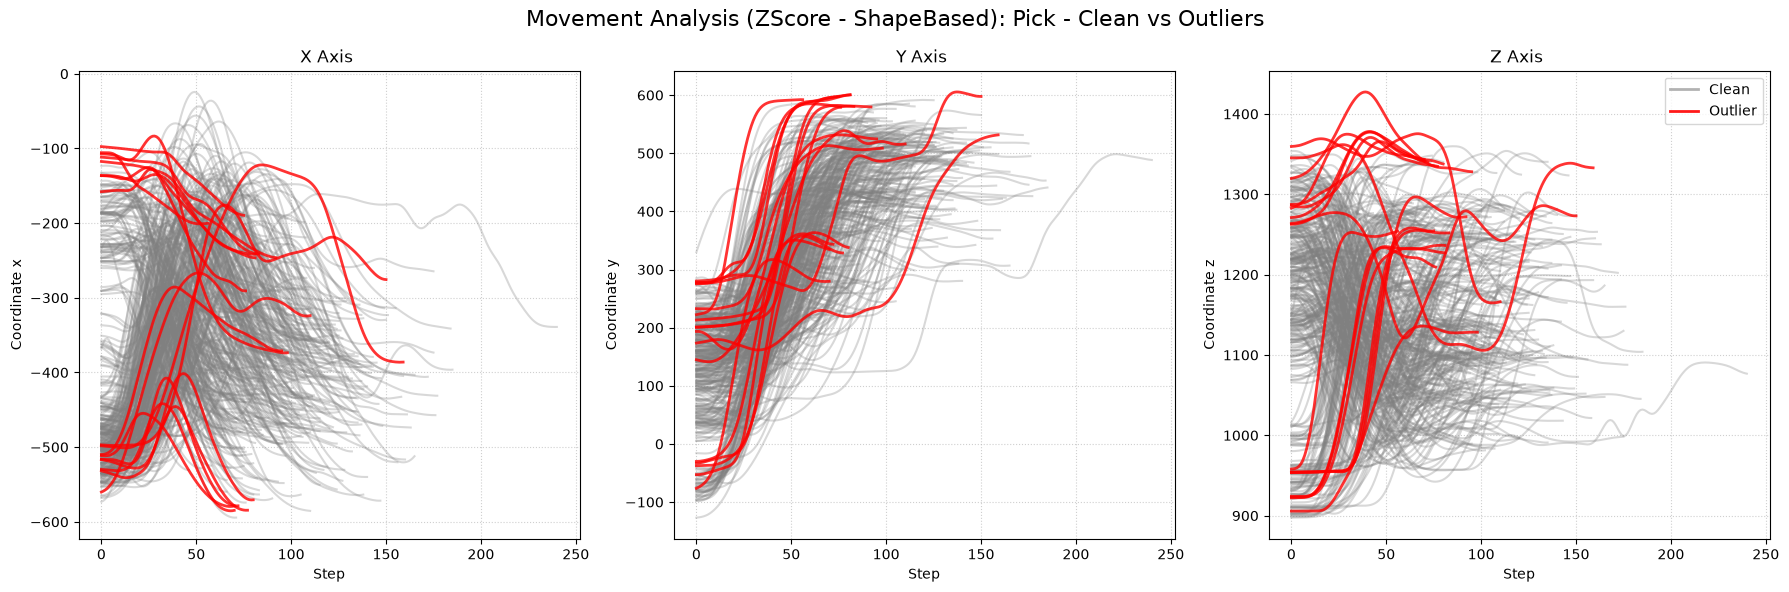

In [30]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION
)